Cell 1 : Install TensorFlow.js converter

In [1]:
!pip install -q tensorflowjs
print("Done")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 89.1/89.1 kB 4.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.0/53.0 kB 2.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.1/16.1 MB 62.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 645.0/645.0 MB 2.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 79.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.5/5.5 MB 108.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.5/72.5 kB 8.5 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
db-dtypes 1.7.1 requires packaging>=24.2.0, but you have packaging 23.2 which is incompatible.
tensorflow-text 2.20.1 requires tensorflow<2.21,>=2.20.0, but you have tensorflow 2.19.0 which is incompatible.
ydf-tf 2.20.0 requires tensorflow==2.20.0, but you have tensorflow 2.1

Cell 2 : Upload your JSON

In [2]:
from google.colab import files
import json

uploaded = files.upload()   # pick nsl_landmarks_letters.json

filename = list(uploaded.keys())[0]
with open(filename) as f:
    payload = json.load(f)

CLASSES = payload["classes"]
data = payload["data"]

print("Classes:", CLASSES)
print("Samples per class:")
for c in CLASSES:
    print(f"  {c}: {len(data[c])}")
print("Total:", sum(len(data[c]) for c in CLASSES))

Saving nsl_landmarks_letters.json to nsl_landmarks_letters.json
Classes: ['B', 'C', 'D', 'I', 'L', 'O', 'V', 'W', 'Y']
Samples per class:
  B: 54
  C: 92
  D: 98
  I: 85
  L: 87
  O: 80
  V: 79
  W: 84
  Y: 103
Total: 762


Cell 3 : Build the arrays

In [3]:
import numpy as np

X, y = [], []
for idx, cls in enumerate(CLASSES):
    for sample in data[cls]:
        X.append(sample)
        y.append(idx)

X = np.array(X, dtype=np.float32)
y = np.array(y, dtype=np.int32)

print("X shape:", X.shape)   # expect (num_samples, 63)
print("y shape:", y.shape)
print("Any NaNs?", np.isnan(X).any())

X shape: (762, 63)
y shape: (762,)
Any NaNs? False


Cell 4 : Split into train and test

In [4]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Train:", X_train.shape[0], "samples")
print("Test: ", X_test.shape[0], "samples")

Train: 609 samples
Test:  153 samples


Cell 5 : Sanity check with KNN

In [5]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

knn = KNeighborsClassifier(n_neighbors=3)
knn.fit(X_train, y_train)
knn_acc = accuracy_score(y_test, knn.predict(X_test))
print(f"KNN baseline accuracy: {knn_acc:.1%}")

KNN baseline accuracy: 96.7%


👆This is a quick baseline before we train the real model. If KNN gets 90%+, your data is clean and separable. If it's below 70%, something's wrong with the recording and we should fix that before training.

Cell 6 : Build and train the neural network

In [6]:
import tensorflow as tf
from tensorflow import keras

tf.random.set_seed(42)

model = keras.Sequential([
    keras.layers.Input(shape=(63,)),
    keras.layers.Dense(64, activation='relu'),
    keras.layers.Dropout(0.3),
    keras.layers.Dense(32, activation='relu'),
    keras.layers.Dropout(0.2),
    keras.layers.Dense(len(CLASSES), activation='softmax')
])

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

history = model.fit(
    X_train, y_train,
    validation_data=(X_test, y_test),
    epochs=150,
    batch_size=16,
    verbose=0,
    callbacks=[
        keras.callbacks.EarlyStopping(
            monitor='val_accuracy', patience=25,
            restore_best_weights=True, mode='max'
        )
    ]
)

print(f"\nFinal train accuracy: {history.history['accuracy'][-1]:.1%}")
print(f"Final test accuracy:  {history.history['val_accuracy'][-1]:.1%}")

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         4,096 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 9)              │           297 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,473 (25.29 KB)

 Trainable params: 6,473 (25.29 KB)

 Non-trainable params: 0 (0.00 B)


Final train accuracy: 96.2%
Final test accuracy:  97.4%


Cell 7 : Plot training curves

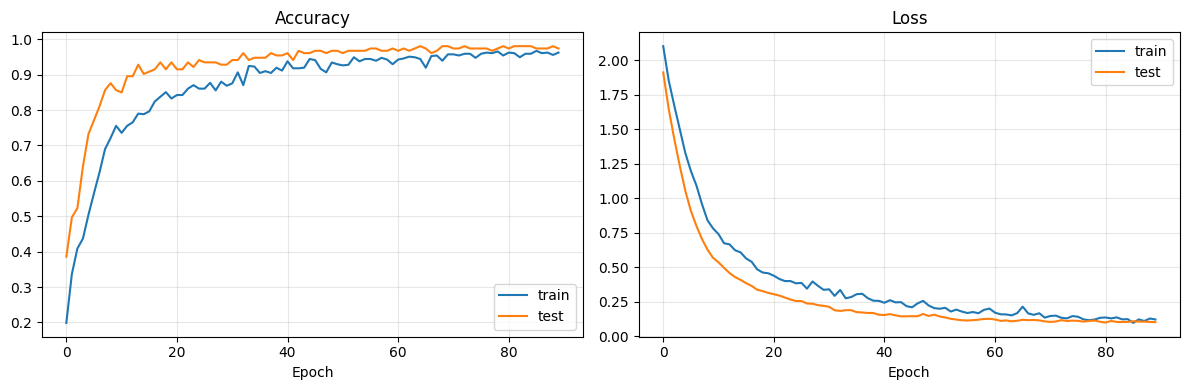

In [7]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history.history['accuracy'], label='train')
axes[0].plot(history.history['val_accuracy'], label='test')
axes[0].set_title('Accuracy')
axes[0].set_xlabel('Epoch')
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(history.history['loss'], label='train')
axes[1].plot(history.history['val_loss'], label='test')
axes[1].set_title('Loss')
axes[1].set_xlabel('Epoch')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

Cell 8 : Confusion matrix

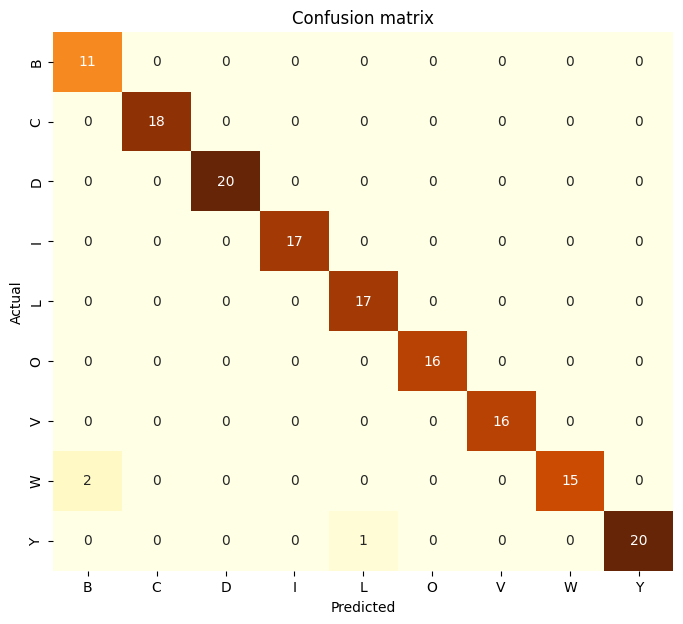

              precision    recall  f1-score   support

           B       0.85      1.00      0.92        11
           C       1.00      1.00      1.00        18
           D       1.00      1.00      1.00        20
           I       1.00      1.00      1.00        17
           L       0.94      1.00      0.97        17
           O       1.00      1.00      1.00        16
           V       1.00      1.00      1.00        16
           W       1.00      0.88      0.94        17
           Y       1.00      0.95      0.98        21

    accuracy                           0.98       153
   macro avg       0.98      0.98      0.98       153
weighted avg       0.98      0.98      0.98       153



In [8]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

y_pred = model.predict(X_test, verbose=0).argmax(axis=1)

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 7))
sns.heatmap(cm, annot=True, fmt='d', cmap='YlOrBr',
            xticklabels=CLASSES, yticklabels=CLASSES, cbar=False)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion matrix')
plt.show()

print(classification_report(y_test, y_pred, target_names=CLASSES))

Cell 9 : Export for the browser

In [10]:
import json, numpy as np
from google.colab import files

# Extract every layer's weights as plain nested lists
weights_out = []
for layer in model.layers:
    w = layer.get_weights()
    if len(w) == 2:  # Dense layer: kernel + bias
        weights_out.append({
            "name": layer.name,
            "kernel": w[0].tolist(),
            "bias": w[1].tolist()
        })

payload = {
    "classes": CLASSES,
    "architecture": [
        {"units": 64, "activation": "relu"},
        {"units": 32, "activation": "relu"},
        {"units": len(CLASSES), "activation": "softmax"}
    ],
    "inputDim": 63,
    "weights": weights_out
}

with open('nsl_model_letters.json', 'w') as f:
    json.dump(payload, f)

import os
size = os.path.getsize('nsl_model_letters.json')
print(f"Exported nsl_model_letters.json ({size:,} bytes)")
print("Layers exported:", [w['name'] for w in weights_out])

files.download('nsl_model_letters.json')

Exported nsl_model_letters.json (138,725 bytes)
Layers exported: ['dense', 'dense_1', 'dense_2']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [13]:
import json
with open('nsl_model_letters.json') as f:
    check = json.load(f)

print("Classes:", check['classes'])
print("Input dim:", check['inputDim'])
for w in check['weights']:
    print(f"  {w['name']}: kernel {len(w['kernel'])}x{len(w['kernel'][0])}, bias {len(w['bias'])}")

Classes: ['B', 'C', 'D', 'I', 'L', 'O', 'V', 'W', 'Y']
Input dim: 63
  dense: kernel 63x64, bias 64
  dense_1: kernel 64x32, bias 32
  dense_2: kernel 32x9, bias 9
